# Assignment 3 · Part 1 — Model comparison and hyper-parameter tuning
## Predicting failed public-procurement contracts in Kazakhstan

**Author:** Aziz Abdulin · **Project:** Tender Risk ML · **Repository:** https://github.com/awzwz/tender-risk-ml

The midterm trained a class-weighted logistic regression (test PR-AUC 0.262). This notebook asks **how much of the
remaining gap a better model can close on the same information**: four model families are compared on the same
20 features, each is tuned, and the effect of tuning, of the decision threshold and of probability calibration is
measured separately. New information (lot text, customer–supplier history) is the subject of the next notebooks;
keeping the features fixed here is what makes the comparison interpretable.

| § | Content | A3 criterion |
|---|---|---|
| 1 | Setup, data, evaluation protocol | — |
| 2 | The four models and why they were chosen | 1 · Comparison of models |
| 3 | Default configurations | 1 |
| 4 | Hyper-parameter tuning: grid search and Optuna | 2 · Hyper-parameter tuning |
| 5 | Before / after: tuning, decision threshold, calibration | 6 · Optimisation of a classical model |
| 6 | Final comparison on the test period | 1, 2, 6 |
| 7 | Conclusions and what goes forward | — |

**How to run:** `Kernel → Restart & Run All`. The first run performs the full search (≈ 30–40 minutes on a laptop
CPU); Optuna studies are stored in `results/a3_04/optuna.db`, so later runs reuse finished trials and take a few
minutes. The data is downloaded from the GitHub release if it is not present.

## 1. Setup, data and evaluation protocol

In [1]:
# Google Colab only: uncomment and run this cell first.
# !git clone -q https://github.com/awzwz/tender-risk-ml
# import os; os.chdir("tender-risk-ml/notebooks")
# !pip install -q catboost optuna

In [2]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import optuna
from catboost import CatBoostClassifier
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prepare as P

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RES = ROOT / "results" / "a3_04"; RES.mkdir(parents=True, exist_ok=True)
PRED = ROOT / "data" / "predictions"; PRED.mkdir(parents=True, exist_ok=True)
STORAGE = f"sqlite:///{(RES / 'optuna.db').as_posix()}"
sns.set_theme(style="whitegrid", context="notebook")
COL = {"Logistic regression": "#2b6cb0", "Random forest": "#2f855a", "LightGBM": "#c05621", "CatBoost": "#6b46c1",
       "Prior": "#a0aec0"}

In [3]:
df = P.load_model_table(ROOT)
X, y = P.FEATURES, P.TARGET
train, val, test = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
y_tr, y_va, y_te = train[y].to_numpy(), val[y].to_numpy(), test[y].to_numpy()

assert train.publish_dt.max() < val.publish_dt.min() < val.publish_dt.max() < test.publish_dt.min()
pd.DataFrame({s: {"rows": len(d), "failed": int(d[y].sum()), "failure rate": d[y].mean(),
                  "from": d.publish_dt.min().date(), "to": d.publish_dt.max().date()}
              for s, d in (("train", train), ("val", val), ("test", test))}).T

,rows,failed,failure rate,from,to
train,266294,17530,0.066,2024-01-01,2024-02-29
val,53514,3683,0.069,2024-03-01,2024-03-15
test,38981,2567,0.066,2024-03-16,2024-03-31


**Protocol (the same as the midterm, so numbers are comparable).**

* Features: the **20 midterm features** (9 numeric, 8 binary, 3 categorical), all known when the winner is chosen.
* Chronological split: models are **fitted on train** (Jan–Feb 2024); every choice — hyper-parameters, early
  stopping, decision threshold, calibration — is made on **validation** (1–15 March); **test** (16–31 March) is
  scored once, in §6.
* Selection metric: **PR-AUC** (average precision). With 6.6 % positives, accuracy is uninformative and ROC-AUC is
  optimistic; PR-AUC measures how clean the top of the ranked list is, which is how an auditor uses the model.
  Reported next to it: ROC-AUC, F1 / precision / recall at the threshold chosen on validation, precision in the top
  1 % (`P@1%`), recall in the top 5 % (`R@5%`) and the Brier score (quality of the probabilities themselves).
* Differences on test come with a **paired bootstrap 95 % interval** (1,000 resamples of test procurements): many
  differences in this project are below 0.01, and without an interval they cannot be interpreted.

In [4]:
def top_k(y_true, p, k):
    # precision in the top k share and recall of the top k share
    n = int(len(p) * k); idx = np.argsort(-p)[:n]
    return y_true[idx].mean(), y_true[idx].sum() / y_true.sum()

def f1_threshold(y_true, p):
    # threshold that maximises F1 (chosen on validation, applied unchanged to test)
    pr, rc, th = precision_recall_curve(y_true, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    return float(th[np.argmax(f1[:-1])])

def scores(y_true, p, thr):
    pred = p >= thr
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "F1": f1_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "P@1%": top_k(y_true, p, 0.01)[0],
            "R@5%": top_k(y_true, p, 0.05)[1], "Brier": brier_score_loss(y_true, p)}

rng = np.random.default_rng(SEED)
BOOT = [rng.integers(0, len(y_te), len(y_te)) for _ in range(1000)]
def boot_diff(p_new, p_ref):
    # paired bootstrap of the test PR-AUC difference: mean and 95 % interval
    d = np.array([average_precision_score(y_te[i], p_new[i]) - average_precision_score(y_te[i], p_ref[i]) for i in BOOT])
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)

## 2. The four models and why they were chosen

The A2 analysis established what the data looks like: a rare positive class (1 : 14), skewed numeric features with
missing values, three categorical features with up to 21 levels, a **U-shaped** effect of the number of bidders and
strong **interactions** (procurement method × value). The models below cover the main ways to deal with that.

| Model | Family | Why it is in the comparison | Encoding of the data |
|---|---|---|---|
| Logistic regression | linear | the midterm baseline: the floor every other model must beat, and an interpretable reference | median imputation + missing flags, z-scores, one-hot categories |
| Random forest | bagging of deep trees | the standard non-linear model; captures thresholds and interactions without tuning-sensitive learning rates | median imputation + missing flags, ordinal categories |
| LightGBM | gradient boosting (histogram, leaf-wise) | expected to be the strongest model on medium-size tabular data; native missing values and categories, fast enough to tune properly | native |
| CatBoost | gradient boosting (symmetric trees, ordered target statistics) | a second boosting library with a **different treatment of categorical features**; if both agree, the result is not an artefact of one implementation | native |

Models that were considered and left out (with reasons) are listed in the midterm notebook (§3): kernel SVM and
k-nearest neighbours do not scale to 266 thousand rows and give no calibrated scores; an MLP rarely beats tree
ensembles on tabular data of this size; neural networks on text are the subject of the next notebook.

In [5]:
def lr_pipeline(**params):
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), P.NUM_FEATURES),
        ("bin", "passthrough", P.BIN_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), P.CAT_FEATURES)])
    return make_pipeline(pre, LogisticRegression(max_iter=2000, random_state=SEED, **params))

def rf_pipeline(**params):
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), P.NUM_FEATURES),
        ("bin", "passthrough", P.BIN_FEATURES),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), P.CAT_FEATURES)])
    return make_pipeline(pre, RandomForestClassifier(n_jobs=-1, random_state=SEED, **params))

# LightGBM uses pandas categories, CatBoost uses the category labels as strings
def as_lgb(d):
    d = d[X].copy()
    for c in P.CAT_FEATURES: d[c] = pd.Categorical(d[c], categories=sorted(df[c].dropna().unique()))
    return d

def as_cat(d):
    d = d[X].copy()
    for c in P.CAT_FEATURES: d[c] = d[c].astype(str)
    return d

XL = {s: as_lgb(d) for s, d in (("train", train), ("val", val), ("test", test))}
XC = {s: as_cat(d) for s, d in (("train", train), ("val", val), ("test", test))}
CAT_IDX = [X.index(c) for c in P.CAT_FEATURES]

## 3. Default configurations

"Default" means the configuration a practitioner would start from without any search: the midterm settings for
logistic regression (L2, C = 1, class-weighted) and the library defaults for the three tree models (no class weights,
no early stopping). This is the **before** side of §5.

In [6]:
models, preds, fit_time, configs = {}, {}, {}, {}

def record(name, model, p_val, p_test, seconds, config):
    models[name] = model; preds[name] = {"val": p_val, "test": p_test}
    fit_time[name] = seconds; configs[name] = config

t = time.time(); m = lr_pipeline(penalty="l2", C=1.0, class_weight="balanced").fit(train[X], y_tr)
record("Logistic regression · default", m, m.predict_proba(val[X])[:, 1], m.predict_proba(test[X])[:, 1], time.time() - t,
       {"penalty": "l2", "C": 1.0, "class_weight": "balanced"})

t = time.time(); m = rf_pipeline().fit(train[X], y_tr)
record("Random forest · default", m, m.predict_proba(val[X])[:, 1], m.predict_proba(test[X])[:, 1], time.time() - t, "sklearn defaults")

t = time.time(); m = lgb.LGBMClassifier(random_state=SEED, verbose=-1).fit(XL["train"], y_tr)
record("LightGBM · default", m, m.predict_proba(XL["val"])[:, 1], m.predict_proba(XL["test"])[:, 1], time.time() - t, "lightgbm defaults")

t = time.time(); m = CatBoostClassifier(random_seed=SEED, verbose=0, thread_count=-1).fit(XC["train"], y_tr, cat_features=CAT_IDX)
record("CatBoost · default", m, m.predict_proba(XC["val"])[:, 1], m.predict_proba(XC["test"])[:, 1], time.time() - t, "catboost defaults")

pd.DataFrame({n: {"val PR-AUC": average_precision_score(y_va, p["val"]), "val ROC-AUC": roc_auc_score(y_va, p["val"]),
                  "fit, s": fit_time[n]} for n, p in preds.items()}).T

,val PR-AUC,val ROC-AUC,"fit, s"
Logistic regression · default,0.290,0.794,4.685
Random forest · default,0.290,0.779,23.412
LightGBM · default,0.340,0.810,2.788
CatBoost · default,0.322,0.807,231.443


Without any tuning the two boosting models are already ahead of the linear baseline on validation, which confirms
the midterm diagnosis that part of the signal sits in non-linear effects and interactions. The default random forest
is not: scikit-learn grows every tree to full depth, and with a 1 : 14 class ratio such trees memorise individual
procurements — it only becomes competitive once the leaf size and the number of features per split are tuned (§4).

## 4. Hyper-parameter tuning

**Objective.** Every configuration is fitted on train and scored by **PR-AUC on validation** — the same split the
final model will face (earlier data → later data). Cross-validation with random folds was rejected: it would mix
January and March procurements and reward configurations that exploit time-specific patterns.

**Methods.**
* *Logistic regression — exhaustive grid search* (`GridSearchCV` with a `PredefinedSplit`: one fold = train → val).
  It has three hyper-parameters with few sensible values (42 combinations), so a full grid is cheap and transparent.
* *Random forest, LightGBM, CatBoost — Bayesian optimisation with Optuna (TPE sampler).* They have 5–9 interacting
  continuous parameters; a grid would need thousands of fits, while TPE concentrates trials in promising regions.
  Budgets: 30 / 50 / 30 trials. The pilot study showed LightGBM's search converging after 15–20 trials, so more trials
  would mostly increase the risk of fitting the validation period.
* *Early stopping* (boosting only): up to 5,000 (LightGBM) / 3,000 (CatBoost) trees, stopped after 100 rounds without
  improvement of validation PR-AUC; the number of trees is therefore chosen together with the other parameters.

Search spaces (log scale where the order of magnitude matters):

| Model | Parameters and ranges |
|---|---|
| Logistic regression | penalty L1 / L2; C ∈ {0.001, 0.01, 0.1, 0.3, 1, 3, 10}; weight of the failure class 1 / 5 / balanced (≈ 14) |
| Random forest | trees 200–800; max depth 6–30 or unlimited; min samples per leaf 5–200 (log); max features 0.1–0.8; class weight none / balanced / balanced subsample |
| LightGBM | learning rate 0.01–0.2 (log); leaves 15–255 (log); min samples per leaf 20–1,000 (log); feature fraction 0.4–1; bagging fraction 0.5–1 and frequency 0–5; L1, L2 1e-8–10 (log); positive-class weight 1–14 |
| CatBoost | depth 4–10; learning rate 0.02–0.2 (log); L2 leaf regularisation 1–30 (log); random strength 0–5; class weights none / balanced |

In [7]:
# ── Logistic regression: full grid, one predefined train → validation fold ──
tv = pd.concat([train, val], ignore_index=True)
fold = PredefinedSplit(np.r_[np.full(len(train), -1), np.zeros(len(val), dtype=int)])
grid = {"logisticregression__penalty": ["l1", "l2"],
        "logisticregression__C": [0.001, 0.01, 0.1, 0.3, 1, 3, 10],
        "logisticregression__class_weight": [None, {0: 1, 1: 5}, "balanced"]}
grid_file = RES / "lr_grid.json"                 # the grid takes ≈ 10 minutes; its results are cached
if grid_file.exists():
    lr_grid = pd.read_json(grid_file)
else:
    t = time.time()
    gs = GridSearchCV(lr_pipeline(solver="liblinear"), grid, scoring="average_precision", cv=fold, n_jobs=-1, refit=False)
    gs.fit(tv[X], tv[y])
    lr_grid = (pd.DataFrame(gs.cv_results_["params"]).rename(columns=lambda c: c.split("__")[1])
               .assign(val_pr_auc=gs.cv_results_["mean_test_score"]))
    lr_grid["class_weight"] = lr_grid.class_weight.map(lambda w: "none" if w is None else "1:5" if isinstance(w, dict) else w)
    lr_grid.to_json(grid_file); print(f"{len(lr_grid)} configurations in {time.time() - t:.0f} s")
lr_grid = lr_grid.sort_values("val_pr_auc", ascending=False).reset_index(drop=True)
lr_grid.head(8)

42 configurations in 2988 s


,C,class_weight,penalty,val_pr_auc
0,0.100,none,l1,0.306
1,0.300,none,l1,0.306
2,0.300,none,l2,0.306
3,1.000,none,l2,0.306
4,0.100,none,l2,0.306
5,1.000,none,l1,0.306
6,3.000,none,l2,0.306
7,3.000,none,l1,0.306


In [8]:
# refit the best grid configuration on train only (refit=False above: GridSearchCV would refit on train + val)
cw = {"none": None, "1:5": {0: 1, 1: 5}, "balanced": "balanced"}
best_lr = {"penalty": lr_grid.penalty[0], "C": float(lr_grid.C[0]), "class_weight": cw[lr_grid.class_weight[0]]}
t = time.time(); m = lr_pipeline(solver="liblinear", **best_lr).fit(train[X], y_tr)
record("Logistic regression · tuned", m, m.predict_proba(val[X])[:, 1], m.predict_proba(test[X])[:, 1], time.time() - t, best_lr)
best_lr

{'penalty': 'l1', 'C': 0.1, 'class_weight': None}

In [9]:
def run_study(name, objective, n_trials):
    # Optuna study stored in SQLite: a re-run only performs the trials that are still missing
    study = optuna.create_study(study_name=name, storage=STORAGE, direction="maximize", load_if_exists=True,
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    todo = n_trials - len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
    t = time.time()
    if todo > 0:
        study.optimize(objective, n_trials=todo)
    print(f"{name}: {len(study.trials)} trials (ran {max(todo, 0)} now, {time.time() - t:.0f} s); "
          f"best val PR-AUC {study.best_value:.4f}")
    return study

def rf_objective(trial):
    depth = trial.suggest_int("max_depth", 6, 31)            # 31 stands for "unlimited"
    params = dict(n_estimators=trial.suggest_int("n_estimators", 200, 800, step=100),
                  max_depth=None if depth == 31 else depth,
                  min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 200, log=True),
                  max_features=trial.suggest_float("max_features", 0.1, 0.8),
                  class_weight=trial.suggest_categorical("class_weight", ["none", "balanced", "balanced_subsample"]))
    params["class_weight"] = None if params["class_weight"] == "none" else params["class_weight"]
    m = rf_pipeline(**params).fit(train[X], y_tr)
    return average_precision_score(y_va, m.predict_proba(val[X])[:, 1])

rf_study = run_study("random_forest", rf_objective, 30)

random_forest: 30 trials (ran 0 now, 0 s); best val PR-AUC 0.3328


In [10]:
def lgb_params(trial):
    return dict(learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
                min_child_samples=trial.suggest_int("min_child_samples", 20, 1000, log=True),
                colsample_bytree=trial.suggest_float("feature_fraction", 0.4, 1.0),
                subsample=trial.suggest_float("bagging_fraction", 0.5, 1.0),
                subsample_freq=trial.suggest_int("bagging_freq", 0, 5),
                reg_alpha=trial.suggest_float("lambda_l1", 1e-8, 10, log=True),
                reg_lambda=trial.suggest_float("lambda_l2", 1e-8, 10, log=True),
                scale_pos_weight=trial.suggest_float("scale_pos_weight", 1, 14))

def fit_lgb(params):
    m = lgb.LGBMClassifier(n_estimators=5000, random_state=SEED, verbose=-1, **params)
    m.fit(XL["train"], y_tr, eval_set=[(XL["val"], y_va)], eval_metric="average_precision",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m

def lgb_objective(trial):
    m = fit_lgb(lgb_params(trial))
    trial.set_user_attr("best_iteration", int(m.best_iteration_))
    return average_precision_score(y_va, m.predict_proba(XL["val"])[:, 1])

lgb_study = run_study("lightgbm", lgb_objective, 50)

lightgbm: 50 trials (ran 0 now, 0 s); best val PR-AUC 0.3414


In [11]:
def cat_params(trial):
    w = trial.suggest_categorical("auto_class_weights", ["none", "Balanced"])
    return dict(depth=trial.suggest_int("depth", 4, 10),
                learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
                l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1, 30, log=True),
                random_strength=trial.suggest_float("random_strength", 0, 5),
                auto_class_weights=None if w == "none" else w)

def fit_cat(params):
    m = CatBoostClassifier(iterations=3000, eval_metric="PRAUC", random_seed=SEED, verbose=0, thread_count=-1, **params)
    m.fit(XC["train"], y_tr, cat_features=CAT_IDX, eval_set=(XC["val"], y_va), early_stopping_rounds=100)
    return m

def cat_objective(trial):
    m = fit_cat(cat_params(trial))
    trial.set_user_attr("best_iteration", int(m.get_best_iteration()))
    return average_precision_score(y_va, m.predict_proba(XC["val"])[:, 1])

cat_study = run_study("catboost", cat_objective, 30)

catboost: 30 trials (ran 0 now, 0 s); best val PR-AUC 0.3472


**Convergence.** The curves show the best validation PR-AUC found after *n* trials. A curve that is flat long before
the budget ends means more trials would not help; the dashed line is the default configuration of the same model.

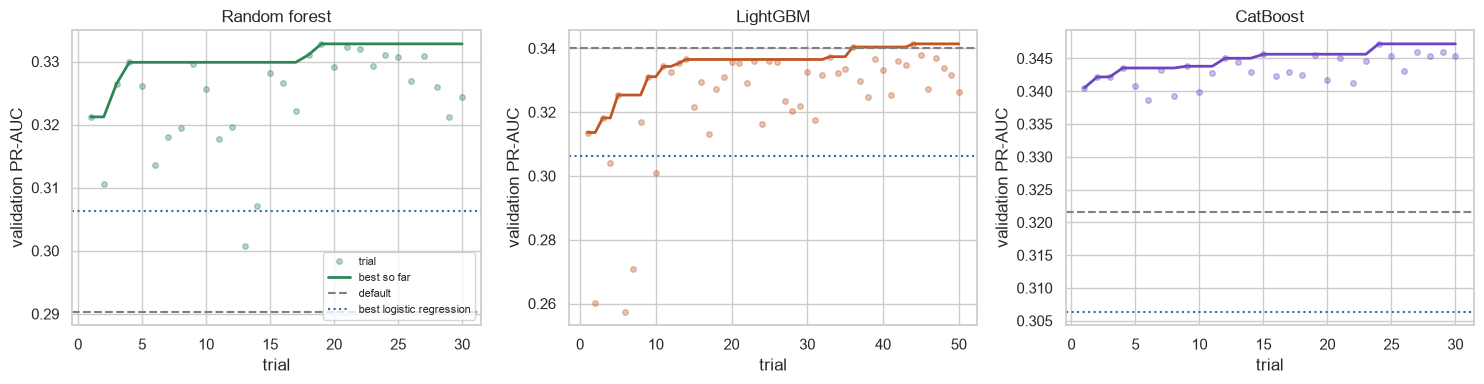

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for a, (name, st, key) in zip(ax, [("Random forest", rf_study, "Random forest · default"),
                                   ("LightGBM", lgb_study, "LightGBM · default"),
                                   ("CatBoost", cat_study, "CatBoost · default")]):
    vals = [t.value for t in st.trials if t.state == optuna.trial.TrialState.COMPLETE]
    a.plot(range(1, len(vals) + 1), vals, "o", color=COL[name], alpha=0.35, ms=4, label="trial")
    a.plot(range(1, len(vals) + 1), np.maximum.accumulate(vals), color=COL[name], lw=2, label="best so far")
    a.axhline(average_precision_score(y_va, preds[key]["val"]), ls="--", color="grey", label="default")
    a.axhline(lr_grid.val_pr_auc.max(), ls=":", color=COL["Logistic regression"], label="best logistic regression")
    a.set(title=name, xlabel="trial", ylabel="validation PR-AUC")
ax[0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "a3_04_convergence.png", dpi=150, bbox_inches="tight"); plt.show()

In [13]:
# Which hyper-parameters matter? (fANOVA importance of each parameter for validation PR-AUC)
imp = pd.DataFrame({name: optuna.importance.get_param_importances(st, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
                    for name, st in (("Random forest", rf_study), ("LightGBM", lgb_study), ("CatBoost", cat_study))})
imp.fillna(0).sort_values("LightGBM", ascending=False).style.format("{:.2f}").background_gradient(axis=0, cmap="Oranges")

,Random forest,LightGBM,CatBoost
learning_rate,0.00,0.64,0.09
scale_pos_weight,0.00,0.08,0.00
min_child_samples,0.00,0.07,0.00
bagging_freq,0.00,0.07,0.00
num_leaves,0.00,0.07,0.00
bagging_fraction,0.00,0.06,0.00
lambda_l2,0.00,0.01,0.00
feature_fraction,0.00,0.00,0.00
lambda_l1,0.00,0.00,0.00
random_strength,0.00,0.00,0.09


In [14]:
pd.DataFrame({"Random forest": rf_study.best_params, "LightGBM": lgb_study.best_params, "CatBoost": cat_study.best_params}) \
  .rename_axis("best value").fillna("")

,Random forest,LightGBM,CatBoost
best value,,,
max_depth,13,,
n_estimators,600,,
min_samples_leaf,10,,
max_features,0.255,,
class_weight,none,,
learning_rate,,0.011,0.037
num_leaves,,66.000,
min_child_samples,,192.000,
feature_fraction,,0.799,


In [15]:
# How many trees did early stopping keep? (number of boosting rounds at the best validation PR-AUC)
iters = {name: pd.Series([t.user_attrs.get("best_iteration") for t in st.trials if t.state == optuna.trial.TrialState.COMPLETE])
         for name, st in (("LightGBM", lgb_study), ("CatBoost", cat_study))}
pd.DataFrame({k: v.describe(percentiles=[0.25, 0.5, 0.75])[["min", "25%", "50%", "75%", "max"]] for k, v in iters.items()}).T

,min,25%,50%,75%,max
LightGBM,1.000,7.000,9.000,10.000,15.000
CatBoost,138.000,284.750,415.000,631.750,"1,178.000"


**An observation about LightGBM.** In half of the LightGBM trials early stopping kept fewer than ten trees, and the
learning rate alone explains most of the variation between trials: validation PR-AUC reaches its peak almost
immediately and then only fluctuates. The search is effectively choosing *where to stop*, not how to model the data
— another sign that the 20 features hold little signal beyond what a few coarse trees capture. CatBoost, with
symmetric trees and ordered boosting, degrades more slowly and keeps a few hundred trees.

**Robustness of the LightGBM choice.** A configuration that wins on one validation fortnight could be lucky. The
three best LightGBM configurations are therefore re-evaluated on four later weeks *inside* the training period
(expanding window: train on everything before the week, score the week, number of trees fixed from the search).

In [16]:
top3 = sorted([t for t in lgb_study.trials if t.state == optuna.trial.TrialState.COMPLETE], key=lambda t: -t.value)[:3]
week = train.publish_dt.dt.isocalendar().week.to_numpy()
last_weeks = sorted(np.unique(week))[-4:]
rows = []
for rank, tr_ in enumerate(top3, 1):
    p = {k: v for k, v in tr_.params.items()}
    params = dict(learning_rate=p["learning_rate"], num_leaves=p["num_leaves"], min_child_samples=p["min_child_samples"],
                  colsample_bytree=p["feature_fraction"], subsample=p["bagging_fraction"], subsample_freq=p["bagging_freq"],
                  reg_alpha=p["lambda_l1"], reg_lambda=p["lambda_l2"], scale_pos_weight=p["scale_pos_weight"])
    fold_scores = []
    for w in last_weeks:
        fit_idx, ev_idx = week < w, week == w
        m = lgb.LGBMClassifier(n_estimators=tr_.user_attrs["best_iteration"], random_state=SEED, verbose=-1, **params)
        m.fit(XL["train"][fit_idx], y_tr[fit_idx])
        fold_scores.append(average_precision_score(y_tr[ev_idx], m.predict_proba(XL["train"][ev_idx])[:, 1]))
    rows.append({"rank on validation": rank, "trial": tr_.number, "validation PR-AUC": tr_.value,
                 "weekly PR-AUC, mean": np.mean(fold_scores), "weekly PR-AUC, std": np.std(fold_scores)})
robust = pd.DataFrame(rows).set_index("rank on validation"); robust

,trial,validation PR-AUC,"weekly PR-AUC, mean","weekly PR-AUC, std"
rank on validation,,,,
1,43,0.341,0.289,0.013
2,35,0.340,0.282,0.016
3,44,0.338,0.287,0.012


If the configuration ranked first on validation is also at or near the top on the weekly folds, it is kept; the
weekly folds are a check, not a second selection criterion (they are part of the training data).

In [17]:
best_lgb = lgb_study.best_trial.params
t = time.time()
m = fit_lgb(dict(learning_rate=best_lgb["learning_rate"], num_leaves=best_lgb["num_leaves"],
                 min_child_samples=best_lgb["min_child_samples"], colsample_bytree=best_lgb["feature_fraction"],
                 subsample=best_lgb["bagging_fraction"], subsample_freq=best_lgb["bagging_freq"],
                 reg_alpha=best_lgb["lambda_l1"], reg_lambda=best_lgb["lambda_l2"],
                 scale_pos_weight=best_lgb["scale_pos_weight"]))
record("LightGBM · tuned", m, m.predict_proba(XL["val"])[:, 1], m.predict_proba(XL["test"])[:, 1], time.time() - t,
       {**best_lgb, "n_estimators": int(m.best_iteration_)})

best_rf = rf_study.best_params
t = time.time()
m = rf_pipeline(n_estimators=best_rf["n_estimators"], max_depth=None if best_rf["max_depth"] == 31 else best_rf["max_depth"],
                min_samples_leaf=best_rf["min_samples_leaf"], max_features=best_rf["max_features"],
                class_weight=None if best_rf["class_weight"] == "none" else best_rf["class_weight"]).fit(train[X], y_tr)
record("Random forest · tuned", m, m.predict_proba(val[X])[:, 1], m.predict_proba(test[X])[:, 1], time.time() - t, best_rf)

best_cat = cat_study.best_params
t = time.time()
m = fit_cat(dict(depth=best_cat["depth"], learning_rate=best_cat["learning_rate"], l2_leaf_reg=best_cat["l2_leaf_reg"],
                 random_strength=best_cat["random_strength"],
                 auto_class_weights=None if best_cat["auto_class_weights"] == "none" else best_cat["auto_class_weights"]))
record("CatBoost · tuned", m, m.predict_proba(XC["val"])[:, 1], m.predict_proba(XC["test"])[:, 1], time.time() - t,
       {**best_cat, "iterations": int(m.get_best_iteration())})
print({k: round(v, 1) for k, v in fit_time.items()})

{'Logistic regression · default': 4.7, 'Random forest · default': 23.4, 'LightGBM · default': 2.8, 'CatBoost · default': 231.4, 'Logistic regression · tuned': 84.9, 'LightGBM · tuned': 6.1, 'Random forest · tuned': 82.7, 'CatBoost · tuned': 63.6}


## 5. Before / after: what each optimisation changes

Three different "optimisations" of a classical model are measured separately, because they improve different things:

1. **Hyper-parameter tuning** — should improve the *ranking* (PR-AUC, ROC-AUC).
2. **Decision threshold** — does not change the ranking; it decides *where to cut* the list. The default 0.5 is
   meaningless for a 6.6 % class, so the threshold is chosen on validation (maximum F1) and applied unchanged to test.
3. **Probability calibration** — does not change the ranking either; it makes the scores mean what they say
   ("0.30" ≈ 30 % of such procurements fail). Isotonic regression is fitted on validation scores.

### 5.1 Tuning: default vs tuned, per model

In [18]:
families = ["Logistic regression", "Random forest", "LightGBM", "CatBoost"]
rows = []
for fam in families:
    d, t_ = preds[f"{fam} · default"], preds[f"{fam} · tuned"]
    mean, lo, hi = boot_diff(t_["test"], d["test"])
    rows.append({"model": fam,
                 "val default": average_precision_score(y_va, d["val"]), "val tuned": average_precision_score(y_va, t_["val"]),
                 "test default": average_precision_score(y_te, d["test"]), "test tuned": average_precision_score(y_te, t_["test"]),
                 "test gain": mean, "95 % CI": f"[{lo:+.3f}, {hi:+.3f}]"})
before_after = pd.DataFrame(rows).set_index("model"); before_after

,val default,val tuned,test default,test tuned,test gain,95 % CI
model,,,,,,
Logistic regression,0.290,0.306,0.262,0.280,0.018,"[+0.015, +0.022]"
Random forest,0.290,0.333,0.249,0.290,0.041,"[+0.033, +0.049]"
LightGBM,0.340,0.341,0.303,0.304,0.001,"[-0.007, +0.010]"
CatBoost,0.322,0.347,0.288,0.311,0.023,"[+0.016, +0.030]"


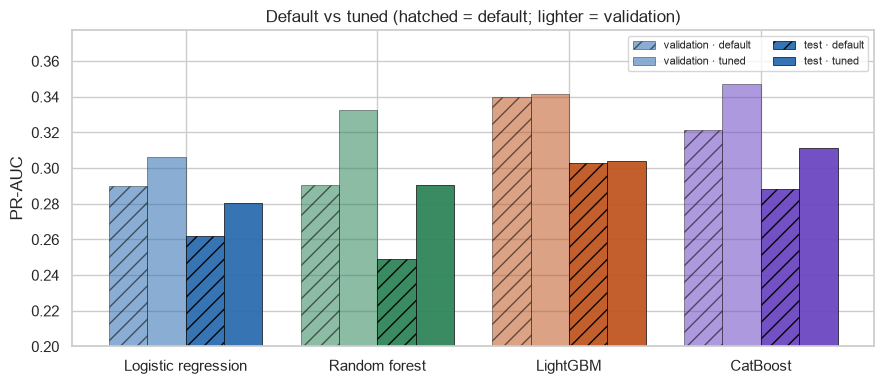

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.2; xs = np.arange(len(families))
for i, (col, lab, hatch) in enumerate([("val default", "validation · default", "//"), ("val tuned", "validation · tuned", ""),
                                        ("test default", "test · default", "//"), ("test tuned", "test · tuned", "")]):
    ax.bar(xs + (i - 1.5) * w, before_after[col], w, label=lab, hatch=hatch, alpha=0.55 if "val" in col else 0.95,
           color=[COL[f] for f in families], edgecolor="black", lw=0.5)
ax.set(xticks=xs, xticklabels=families, ylabel="PR-AUC", ylim=(0.2, before_after.iloc[:, :4].max().max() + 0.03),
       title="Default vs tuned (hatched = default; lighter = validation)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "a3_04_before_after.png", dpi=150, bbox_inches="tight"); plt.show()

### 5.2 Decision threshold

In [20]:
best_name = max([f"{f} · tuned" for f in families], key=lambda n: average_precision_score(y_va, preds[n]["val"]))
p_va, p_te = preds[best_name]["val"], preds[best_name]["test"]
thr_f1 = f1_threshold(y_va, p_va)
thr_budget = float(np.quantile(p_va, 0.95))                 # flag the riskiest 5 % of procurements
thr_rows = {}
for label, thr in (("0.5 (default)", 0.5), (f"max F1 on validation ({thr_f1:.3f})", thr_f1),
                   (f"5 % budget on validation ({thr_budget:.3f})", thr_budget)):
    pred = p_te >= thr
    thr_rows[label] = {"flagged share": pred.mean(), "precision": precision_score(y_te, pred, zero_division=0),
                       "recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred)}
print("model:", best_name)
pd.DataFrame(thr_rows).T

model: CatBoost · tuned


,flagged share,precision,recall,F1
0.5 (default),0.006,0.600,0.050,0.093
max F1 on validation (0.188),0.080,0.340,0.412,0.373
5 % budget on validation (0.249),0.048,0.409,0.300,0.346


### 5.3 Probability calibration

Two calibration methods, both fitted on validation scores and applied to test:
* **Platt scaling** — a logistic regression on the logit of the score; a smooth monotone map, so the ranking is
  unchanged exactly.
* **Isotonic regression** — a free-form non-decreasing step function; more flexible, but it maps ranges of scores to
  the same value, which creates ties and can slightly lower PR-AUC.

They are applied to the class-weighted baseline (whose weighting inflates every score) and to the best tuned model.

In [21]:
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
def platt(pv, pt):
    m = LogisticRegression(C=1e6, max_iter=1000).fit(logit(pv).reshape(-1, 1), y_va)
    return m.predict_proba(logit(pt).reshape(-1, 1))[:, 1]
def isotonic(pv, pt):
    return IsotonicRegression(out_of_bounds="clip").fit(pv, y_va).predict(pt)

lr_name = "Logistic regression · default"
cal_rows = {}
for name in (lr_name, best_name):
    pv_, pt_ = preds[name]["val"], preds[name]["test"]
    cal_rows[f"{name} · raw"] = pt_
    cal_rows[f"{name} · Platt"] = platt(pv_, pt_)
    cal_rows[f"{name} · isotonic"] = isotonic(pv_, pt_)
cal = pd.DataFrame({k: {"Brier": brier_score_loss(y_te, v), "mean score": v.mean(), "actual failure rate": y_te.mean(),
                        "PR-AUC": average_precision_score(y_te, v), "ROC-AUC": roc_auc_score(y_te, v)}
                    for k, v in cal_rows.items()}).T
cal

,Brier,mean score,actual failure rate,PR-AUC,ROC-AUC
Logistic regression · default · raw,0.200,0.415,0.066,0.262,0.792
Logistic regression · default · Platt,0.055,0.069,0.066,0.262,0.792
Logistic regression · default · isotonic,0.055,0.069,0.066,0.255,0.791
CatBoost · tuned · raw,0.053,0.069,0.066,0.311,0.807
CatBoost · tuned · Platt,0.053,0.069,0.066,0.311,0.807
CatBoost · tuned · isotonic,0.053,0.069,0.066,0.303,0.807


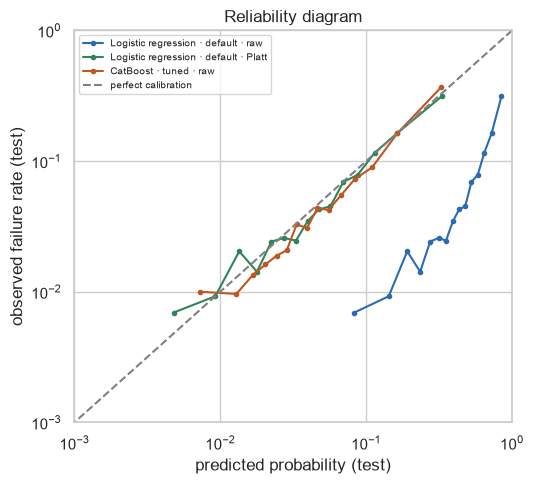

In [22]:
fig, ax = plt.subplots(figsize=(5.5, 5))
show = {k: v for k, v in cal_rows.items() if k in (f"{lr_name} · raw", f"{lr_name} · Platt", f"{best_name} · raw")}
for (label, p), c in zip(show.items(), ["#2b6cb0", "#2f855a", "#c05621"]):
    frac, mean_p = calibration_curve(y_te, p, n_bins=15, strategy="quantile")
    ax.plot(mean_p, frac, "o-", ms=3, color=c, label=label)
ax.plot([0, 1], [0, 1], ls="--", color="grey", label="perfect calibration")
ax.set(xscale="log", yscale="log", xlim=(1e-3, 1), ylim=(1e-3, 1), xlabel="predicted probability (test)",
       ylabel="observed failure rate (test)", title="Reliability diagram")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "a3_04_calibration.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading the table.** The class-weighted baseline is badly calibrated: weighting the rare class 14 : 1 multiplies
its scores, so its average "probability" is several times the real failure rate — fine for ranking, wrong for
reporting a risk level. Platt scaling repairs that completely (Brier drops several-fold) while PR-AUC and ROC-AUC stay
identical, because the ranking does not change. The best tuned model was trained *without* class weights and is
already calibrated; recalibrating it changes nothing useful, and isotonic regression even costs some PR-AUC through
the ties it creates. Calibration is therefore a separate fix for a separate problem: it is needed exactly when the
training loss was reweighted (or the training sample was rebalanced, as for the LLM in notebook 06).

## 6. Final comparison on the test period (16–31 March 2024)

All models, the decision threshold and the calibration were fixed on train / validation; this is the first and only
time test is used. The interval is the paired bootstrap difference in PR-AUC against the midterm baseline.
Fit times were measured while other notebooks were running on the same laptop; only their order of magnitude is
meaningful (logistic regression and LightGBM: seconds; random forest and CatBoost: one to a few minutes).

In [23]:
final_rows = {"Prior (no model)": {**scores(y_te, np.full(len(y_te), y_tr.mean()), 0.5), "fit, s": 0.0}}
ref = preds["Logistic regression · default"]["test"]
for name, p in preds.items():
    thr = f1_threshold(y_va, p["val"])
    row = {**scores(y_te, p["test"], thr), "fit, s": fit_time[name]}
    if name != "Logistic regression · default":
        mean, lo, hi = boot_diff(p["test"], ref)
        row["Δ PR-AUC vs baseline"] = f"{mean:+.3f} [{lo:+.3f}, {hi:+.3f}]"
    final_rows[name] = row
final = pd.DataFrame(final_rows).T
order = ["Prior (no model)"] + [f"{f} · {k}" for f in families for k in ("default", "tuned")]
final = final.loc[order]
final.to_csv(RES / "metrics_test.csv")
final

,ROC-AUC,PR-AUC,F1,precision,recall,P@1%,R@5%,Brier,"fit, s",Δ PR-AUC vs baseline
Prior (no model),0.500,0.066,0.000,0.000,0.000,0.057,0.044,0.062,0.000,NaN
Logistic regression · default,0.792,0.262,0.324,0.263,0.422,0.504,0.263,0.200,4.685,NaN
Logistic regression · tuned,0.791,0.280,0.333,0.282,0.406,0.563,0.279,0.054,84.929,"+0.018 [+0.015, +0.022]"
Random forest · default,0.770,0.249,0.323,0.288,0.367,0.486,0.263,0.056,23.412,"-0.013 [-0.025, +0.000]"
Random forest · tuned,0.803,0.290,0.359,0.337,0.384,0.530,0.293,0.054,82.688,"+0.028 [+0.018, +0.039]"
LightGBM · default,0.805,0.303,0.369,0.323,0.430,0.555,0.308,0.053,2.788,"+0.041 [+0.029, +0.051]"
LightGBM · tuned,0.803,0.304,0.370,0.325,0.430,0.578,0.309,0.059,6.116,"+0.042 [+0.031, +0.053]"
CatBoost · default,0.799,0.288,0.365,0.317,0.429,0.494,0.307,0.054,231.443,"+0.026 [+0.014, +0.038]"
CatBoost · tuned,0.807,0.311,0.373,0.340,0.412,0.573,0.307,0.053,63.550,"+0.049 [+0.039, +0.059]"


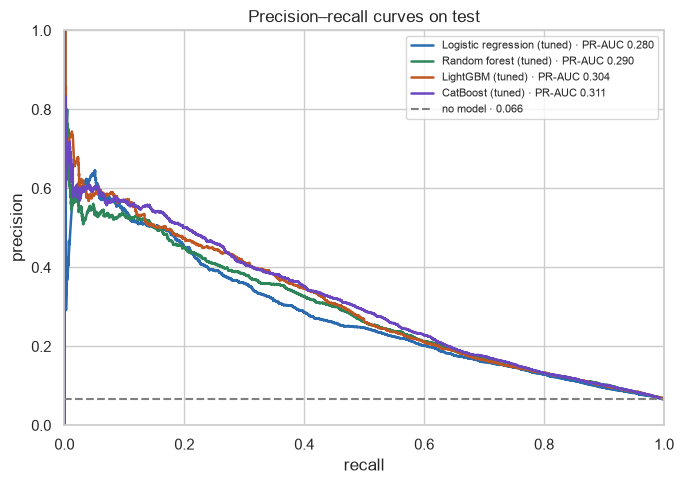

In [24]:
fig, ax = plt.subplots(figsize=(7, 5))
for fam in families:
    p = preds[f"{fam} · tuned"]["test"]
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax.plot(rc, pr, color=COL[fam], lw=1.8, label=f"{fam} (tuned) · PR-AUC {average_precision_score(y_te, p):.3f}")
ax.axhline(y_te.mean(), ls="--", color="grey", label=f"no model · {y_te.mean():.3f}")
ax.set(xlabel="recall", ylabel="precision", title="Precision–recall curves on test", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "a3_04_pr_curves.png", dpi=150, bbox_inches="tight"); plt.show()

In [25]:
# Save everything the later notebooks reuse: scores per procurement, chosen configurations, test metrics
for name, p in preds.items():
    key = name.lower().replace(" · ", "_").replace(" ", "_")
    pd.DataFrame({"id": np.r_[val.id, test.id], "split": ["val"] * len(val) + ["test"] * len(test),
                  "score": np.r_[p["val"], p["test"]]}).to_parquet(PRED / f"04_{key}.parquet", index=False)
(RES / "best_params.json").write_text(json.dumps({k: v for k, v in configs.items()}, indent=2, default=str))
print(sorted(f.name for f in PRED.glob("04_*.parquet")))

['04_catboost_default.parquet', '04_catboost_tuned.parquet', '04_lightgbm_default.parquet', '04_lightgbm_tuned.parquet', '04_logistic_regression_default.parquet', '04_logistic_regression_tuned.parquet', '04_random_forest_default.parquet', '04_random_forest_tuned.parquet']


## 7. Conclusions

The numbers below are read from the tables above; the discussion of what they mean is the research result of this
part of Assignment 3.

In [26]:
g = before_after["test gain"]
best_test = final.loc[[f"{f} · tuned" for f in families], "PR-AUC"].astype(float)
print(f"Best tuned model on test: {best_test.idxmax()} (PR-AUC {best_test.max():.3f}; baseline {final.loc['Logistic regression · default', 'PR-AUC']:.3f})")
print("Test gain from tuning per family:", {k: round(v, 3) for k, v in g.items()})
print(f"Baseline calibration: Brier {cal.loc[f'{lr_name} · raw', 'Brier']:.3f} -> {cal.loc[f'{lr_name} · Platt', 'Brier']:.3f} (Platt), "
      f"PR-AUC {cal.loc[f'{lr_name} · raw', 'PR-AUC']:.3f} -> {cal.loc[f'{lr_name} · Platt', 'PR-AUC']:.3f}")

Best tuned model on test: CatBoost · tuned (PR-AUC 0.311; baseline 0.262)
Test gain from tuning per family: {'Logistic regression': 0.018, 'Random forest': 0.041, 'LightGBM': 0.001, 'CatBoost': 0.023}
Baseline calibration: Brier 0.200 -> 0.055 (Platt), PR-AUC 0.262 -> 0.262


1. **The model family matters more than its settings.** Gradient boosting is the largest single improvement on the
   midterm features: tuned CatBoost reaches test PR-AUC **0.311 against 0.262** for the midterm baseline
   (+0.049, 95 % CI [+0.039, +0.059]), and among the 1 % highest-scored procurements 57 % fail instead of 50 %.
   This confirms the midterm finding that the signal is non-linear (thresholds in value, the U-shape in bidders,
   method × value interactions). Both boosting libraries end within 0.007 of each other, so the result is not an
   artefact of one implementation.
2. **Tuning matters for some models and not for others.**
   * *Random forest:* +0.041 [+0.033, +0.049] — the default fully grown trees overfit (0.249, below the linear
     baseline); limiting depth to 13 and using a quarter of the features per split fixes that. The share of features
     per split alone explains 86 % of the variation between trials.
   * *CatBoost:* +0.023 [+0.016, +0.030] — mainly tree depth (8) and not reweighting the classes.
   * *Logistic regression:* +0.018 [+0.015, +0.022] — the best configuration drops the class weights of the midterm
     (L1, C = 0.1): reweighting helps recall at a threshold but slightly hurts the ranking.
   * *LightGBM:* +0.001 [−0.007, +0.010], no measurable gain. Early stopping keeps only a handful of trees in most
     trials: validation PR-AUC peaks almost at once and the search is choosing *where to stop*.
   After the first 15 trials the best validation PR-AUC improved by only 0.003 (random forest), 0.002 (CatBoost)
   and 0.005 (LightGBM, whose last improvement at trial 44 is itself within the noise of early stopping); the best
   LightGBM configuration on validation is also the best on the weekly folds inside train. More trials would not
   change the picture.
3. **Threshold and calibration solve different problems.** Moving the threshold from 0.5 to the F1-optimal value
   chosen on validation raises test recall from 5 % to 41 % at 34 % precision — the ranking is the same, only the
   cut changes. Calibration repairs the probabilities of the class-weighted baseline (Brier several times lower,
   identical ranking); the tuned CatBoost is trained without weights and is already calibrated.
4. **What goes forward.**
   * *Model of record on the 20 features:* tuned CatBoost.
   * *Workhorse for the feature experiments in notebooks 05–07:* LightGBM with learning rate 0.05 and early stopping.
     The search showed that LightGBM tuning brings nothing on these features, and LightGBM is about 30 times faster
     than CatBoost, which makes ablations and bootstrap intervals affordable. The final model is re-tuned on its own
     feature set in notebook 07.
   * *Where the next gain must come from:* tuning has reached a plateau, so it has to be **new information** about
     each procurement — the text of the lots (notebook 05: transfer learning and fine-tuning) and the
     customer–supplier history (notebook 07) — not more search on the same 20 features.